In [1]:
# If required, uncomment:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
TARGET = "Condition_Class"
CLASS_NAMES = ["Excellent", "Good", "Fair", "Poor"]

In [2]:
TRAIN_PATH = "../training_image_features.csv"
VAL_PATH   = "../validation_image_features.csv"
TEST_PATH  = "../testing_image_features.csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

for name, df in [("Training", train_df), ("Validation", val_df), ("Testing", test_df)]:
    print(f"{name}: {df.shape}")
    print(df[TARGET].value_counts().reindex(CLASS_NAMES, fill_value=0))
    print()

Training: (10058, 43)
Condition_Class
Excellent     100
Good         2176
Fair         6907
Poor          875
Name: count, dtype: int64

Validation: (3237, 43)
Condition_Class
Excellent      40
Good          722
Fair         2183
Poor          292
Name: count, dtype: int64

Testing: (3224, 43)
Condition_Class
Excellent      41
Good          716
Fair         2193
Poor          274
Name: count, dtype: int64



In [3]:
EXCLUDE_COLUMNS = [
    "Condition_Class", "Condition_Score", "Damage_Score",
    "Structural_Integrity", "Recovery_Pathway",
    "Reconditioning_Required", "Recovery_Potential",
    "Alternative_Use_Category", "Alternative_Use_Suitability",
    "Sample_ID", "Image_ID"
]

feature_columns = [c for c in train_df.columns if c not in EXCLUDE_COLUMNS]

X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].astype(str)

X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].astype(str)

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype(str)

numeric_features = X_train.select_dtypes(include=[np.number, "bool"]).columns.tolist()
categorical_features = [c for c in feature_columns if c not in numeric_features]

print("Features used:", len(feature_columns))
print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))
print(feature_columns)

Features used: 32
Numeric: 26
Categorical: 6
['Material_Type', 'Material_Subtype', 'Source', 'Exposure_Type', 'Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Discoloration_Level', 'Deformation_Level', 'Missing_Portion', 'pixel_img_width', 'pixel_img_height', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']


In [4]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
], remainder="drop")

In [5]:
rf_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

ada_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=RANDOM_STATE),
        n_estimators=150,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

cart_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(
        criterion="gini",
        max_depth=best_cart_depth if "best_cart_depth" in globals() else 12,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

svm_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

estimators = [
    ("random_forest", rf_pipeline),
    ("ada_boost", ada_pipeline),
    ("cart", cart_pipeline),
    ("svm", svm_pipeline)
]
print("Base estimators defined:", [name for name, _ in estimators])

Base estimators defined: ['random_forest', 'ada_boost', 'cart', 'svm']


In [6]:
hard_voting = VotingClassifier(
    estimators=estimators,
    voting="hard",
    n_jobs=-1
)

soft_voting = VotingClassifier(
    estimators=estimators,
    voting="soft",
    n_jobs=-1,
    weights=None
)

# Fit both ensembles on the same training split.
# AdaBoost's shallow decision-tree estimator uses balanced class weights.
hard_voting.fit(X_train, y_train)
soft_voting.fit(X_train, y_train)

print("Both voting ensembles trained.")

Both voting ensembles trained.


In [7]:
def calculate_metrics(model, X, y, name):
    pred = model.predict(X)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y, pred),
        "Macro Precision": precision_score(y, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y, pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y, pred, average="weighted", zero_division=0)
    }

validation_results = pd.DataFrame([
    calculate_metrics(hard_voting, X_val, y_val, "Hard Voting"),
    calculate_metrics(soft_voting, X_val, y_val, "Soft Voting")
]).sort_values("Macro F1", ascending=False)

display(validation_results)

best_voting_name = validation_results.iloc[0]["Model"]
best_voting = hard_voting if best_voting_name == "Hard Voting" else soft_voting
print("Selected ensemble:", best_voting_name)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,Soft Voting,0.999073,0.999425,0.992548,0.995946,0.999071
0,Hard Voting,0.990114,0.996152,0.968739,0.981789,0.989927


Selected ensemble: Soft Voting


In [ ]:
y_test_pred = best_voting.predict(X_test)

print("Selected Voting Ensemble:", best_voting_name)
print("Test Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Macro Precision:", round(precision_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("Macro Recall:", round(recall_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, y_test_pred, average="weighted", zero_division=0), 4))

print("\\nClassification Report:")
print(classification_report(y_test, y_test_pred, labels=CLASS_NAMES, zero_division=0))

Selected Voting Ensemble: Soft Voting
Test Accuracy: 0.9988
Macro Precision: 0.9988
Macro Recall: 0.9808
Macro F1: 0.9895
Weighted F1: 0.9987
\nClassification Report:
              precision    recall  f1-score   support

   Excellent       1.00      0.93      0.96        41
        Good       1.00      1.00      1.00       716
        Fair       1.00      1.00      1.00      2193
        Poor       1.00      1.00      1.00       274

    accuracy                           1.00      3224
   macro avg       1.00      0.98      0.99      3224
weighted avg       1.00      1.00      1.00      3224



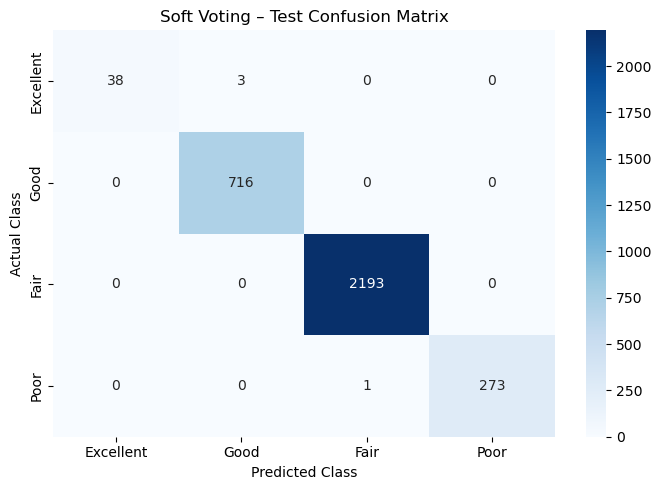

In [9]:
cm = confusion_matrix(y_test, y_test_pred, labels=CLASS_NAMES)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title(f"{best_voting_name} – Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
os.makedirs("saved_models", exist_ok=True)

joblib.dump(best_voting, "saved_models/codd_voting_ensemble.joblib")
print("Saved selected voting ensemble to saved_models/codd_voting_ensemble.joblib")

# Save the fitted component estimators from the selected VotingClassifier.
for estimator_name, fitted_estimator in zip(
    [name for name, _ in estimators],
    best_voting.estimators_
):
    joblib.dump(
        fitted_estimator,
        f"saved_models/codd_voting_{estimator_name}.joblib"
    )

print("Saved all fitted component estimators.")

Saved selected voting ensemble to saved_models/codd_voting_ensemble.joblib
Saved all fitted component estimators.
